In [2]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Se placer à la racine du projet (le dossier qui contient src/)
if os.path.basename(os.path.abspath("")) == "notebooks":
    os.chdir("..")

from src.detector import Detector, CLASSES, predict
from src.train import make_dataset, train, evaluate
from src.visualize import show_images, show_feature_maps, show_detections

SIZE = 64
TRAIN_SAMPLES = 2000
VAL_SAMPLES = 400
BATCH_SIZE = 64
EPOCHS = 30
LR = 3e-3
os.makedirs("outputs", exist_ok=True)

images : torch.Size([400, 3, 64, 64])  cibles : torch.Size([400, 6, 8, 8])
{'cercle': 704, 'carré': 641, 'triangle': 655}


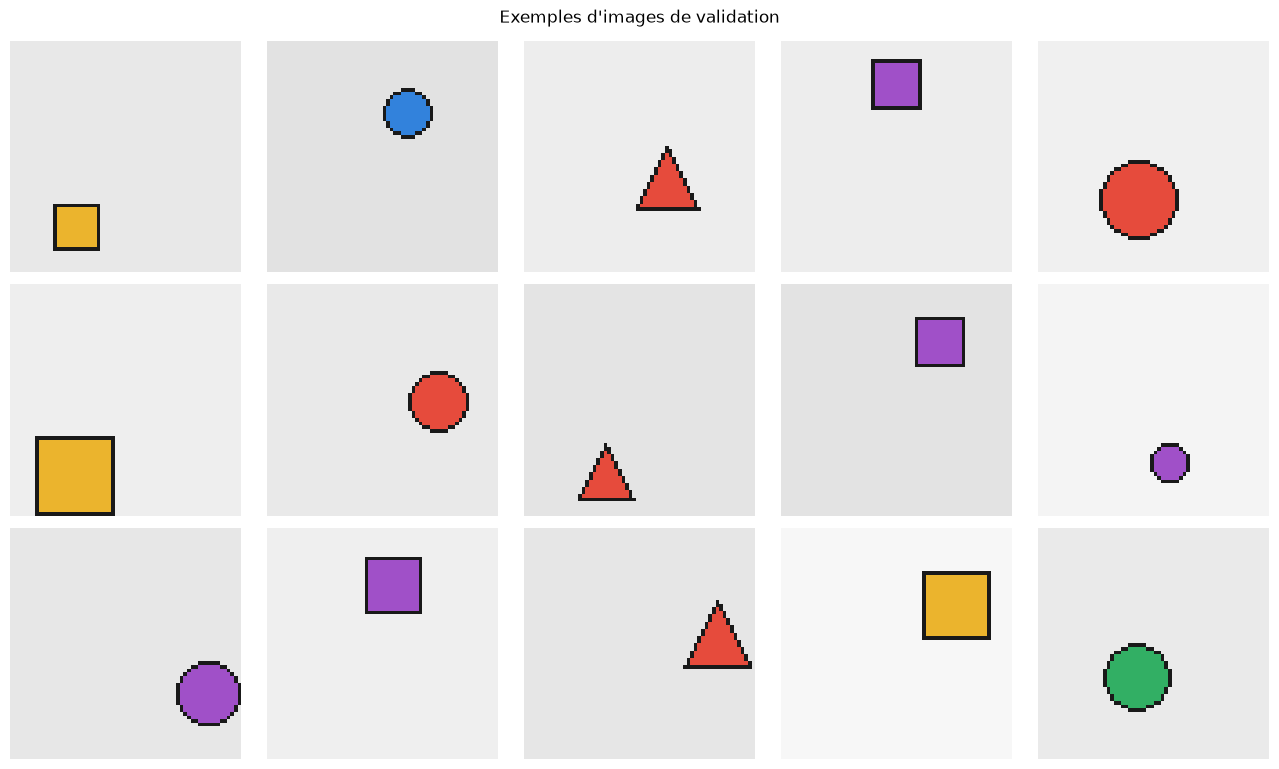

In [13]:
train_set = make_dataset(TRAIN_SAMPLES, seed=7)
val_set = make_dataset(VAL_SAMPLES, seed=8)      # autre graine = images jamais vues
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)

images_val, targets_val = val_set.tensors
print("images :", images_val.shape, " cibles :", targets_val.shape)   # (N, 3, 64, 64) et (N, 6, 8, 8)

# Nombre d'images de chaque forme dans l'entraînement
train_targets = train_set.tensors[1]
pos = train_targets[:, 0] > 0.5
counts = torch.bincount(train_targets[:, 5][pos].long(), minlength=3)
print({CLASSES[k]: int(counts[k]) for k in range(3)})

show_images(list(images_val[:15]), "Exemples d'images de validation")

In [4]:
try:
    from torch.utils.tensorboard import SummaryWriter
except ImportError:          # si tensorboard n'est pas installé, on continue sans
    SummaryWriter = None

def fit(model, name):
    torch.manual_seed(0)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    writer = SummaryWriter(f"runs/{name}") if SummaryWriter else None
    history = {"loss": [], "iou": [], "iou50": [], "classe": []}
    n_params = sum(p.numel() for p in model.parameters())
    print(f"--- {name} : {n_params} paramètres ---")
    for epoch in range(1, EPOCHS + 1):
        loss = train(model, train_loader, optimizer)
        res = evaluate(model, val_loader, SIZE)
        history["loss"].append(loss)
        history["iou"].append(res["iou"])
        history["iou50"].append(res["iou50"])
        history["classe"].append(res["classe"])
        if writer:
            writer.add_scalar("Loss/train", loss, epoch)
            writer.add_scalar("IoU/validation", res["iou"], epoch)
            writer.add_scalar("Accuracy/validation_IoU_gt_0.5", res["iou50"], epoch)
            if res["classe"] is not None:
                writer.add_scalar("Accuracy/validation_classe", res["classe"], epoch)
        texte_classe = "" if res["classe"] is None else f"  bonne classe {res['classe']:.0%}"
        print(f"epoch {epoch:2d}  loss {loss:.4f}  IoU {res['iou']:.3f}  IoU>0.5 {res['iou50']:.0%}{texte_classe}")
    if writer:
        writer.close()
    history["final"] = res
    history["n_params"] = n_params
    return history

In [5]:
torch.manual_seed(0)
model1 = Detector(num_classes=0)
hist1 = fit(model1, "etape1_sans_classe")

--- etape1_sans_classe : 6309 paramètres ---
epoch  1  loss 0.9772  IoU 0.419  IoU>0.5 32%
epoch  2  loss 0.4840  IoU 0.600  IoU>0.5 72%
epoch  3  loss 0.2921  IoU 0.640  IoU>0.5 80%
epoch  4  loss 0.2092  IoU 0.658  IoU>0.5 82%
epoch  5  loss 0.1720  IoU 0.674  IoU>0.5 86%
epoch  6  loss 0.1466  IoU 0.693  IoU>0.5 88%
epoch  7  loss 0.1343  IoU 0.683  IoU>0.5 87%
epoch  8  loss 0.1318  IoU 0.690  IoU>0.5 88%
epoch  9  loss 0.1205  IoU 0.709  IoU>0.5 91%
epoch 10  loss 0.1145  IoU 0.720  IoU>0.5 93%
epoch 11  loss 0.1078  IoU 0.723  IoU>0.5 93%
epoch 12  loss 0.1038  IoU 0.723  IoU>0.5 93%
epoch 13  loss 0.1032  IoU 0.731  IoU>0.5 94%
epoch 14  loss 0.1011  IoU 0.751  IoU>0.5 96%
epoch 15  loss 0.0989  IoU 0.731  IoU>0.5 93%
epoch 16  loss 0.0951  IoU 0.735  IoU>0.5 95%
epoch 17  loss 0.0936  IoU 0.741  IoU>0.5 94%
epoch 18  loss 0.0910  IoU 0.732  IoU>0.5 93%
epoch 19  loss 0.0962  IoU 0.742  IoU>0.5 95%
epoch 20  loss 0.0895  IoU 0.741  IoU>0.5 94%
epoch 21  loss 0.0886  IoU 0.739  I

In [6]:
torch.manual_seed(0)
model2 = Detector(num_classes=3)
hist2 = fit(model2, "etape2_avec_classe")

--- etape2_avec_classe : 6408 paramètres ---
epoch  1  loss 1.8568  IoU 0.421  IoU>0.5 30%  bonne classe 48%
epoch  2  loss 0.9183  IoU 0.537  IoU>0.5 61%  bonne classe 79%
epoch  3  loss 0.5081  IoU 0.604  IoU>0.5 74%  bonne classe 93%
epoch  4  loss 0.3150  IoU 0.641  IoU>0.5 82%  bonne classe 96%
epoch  5  loss 0.2321  IoU 0.654  IoU>0.5 84%  bonne classe 98%
epoch  6  loss 0.1945  IoU 0.675  IoU>0.5 87%  bonne classe 98%
epoch  7  loss 0.1677  IoU 0.689  IoU>0.5 89%  bonne classe 98%
epoch  8  loss 0.1557  IoU 0.684  IoU>0.5 89%  bonne classe 99%
epoch  9  loss 0.1438  IoU 0.695  IoU>0.5 89%  bonne classe 99%
epoch 10  loss 0.1356  IoU 0.704  IoU>0.5 91%  bonne classe 100%
epoch 11  loss 0.1226  IoU 0.716  IoU>0.5 91%  bonne classe 100%
epoch 12  loss 0.1163  IoU 0.718  IoU>0.5 91%  bonne classe 100%
epoch 13  loss 0.1108  IoU 0.721  IoU>0.5 91%  bonne classe 100%
epoch 14  loss 0.1167  IoU 0.721  IoU>0.5 92%  bonne classe 99%
epoch 15  loss 0.1061  IoU 0.725  IoU>0.5 92%  bonne cl

Mesure                   Étape 1 (sans classe)   Étape 2 (avec classe)
Paramètres                                6309                    6408
IoU moyen                                0.733                   0.742
IoU > 0,5                                92.3%                   92.8%
Bonne classe                                 —                   99.8%
Loss train (fin)                        0.0802                  0.0823


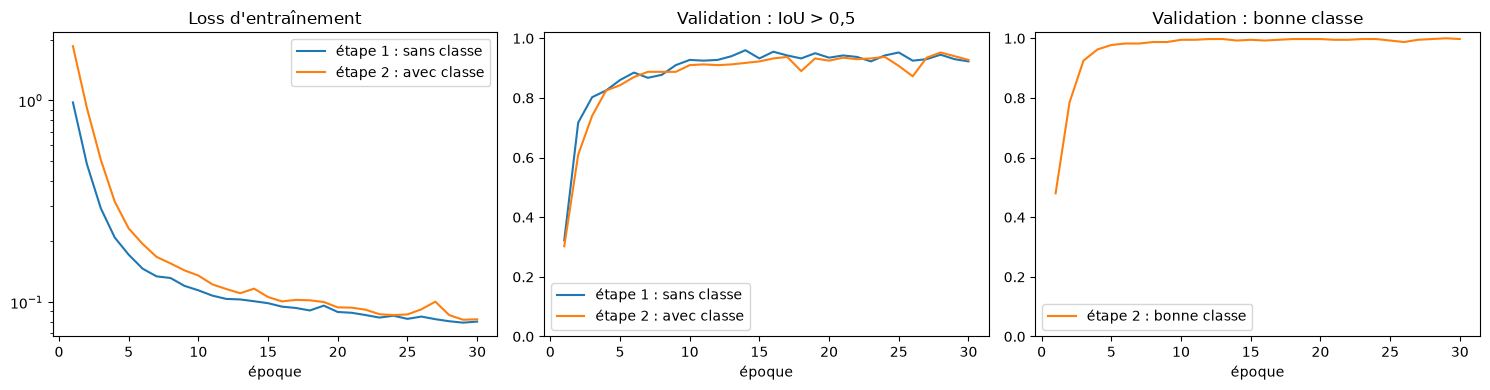

In [7]:
print(f"{'Mesure':<22}{'Étape 1 (sans classe)':>24}{'Étape 2 (avec classe)':>24}")
print(f"{'Paramètres':<22}{hist1['n_params']:>24}{hist2['n_params']:>24}")
print(f"{'IoU moyen':<22}{hist1['final']['iou']:>24.3f}{hist2['final']['iou']:>24.3f}")
print(f"{'IoU > 0,5':<22}{hist1['final']['iou50']:>24.1%}{hist2['final']['iou50']:>24.1%}")
print(f"{'Bonne classe':<22}{'—':>24}{hist2['final']['classe']:>24.1%}")
print(f"{'Loss train (fin)':<22}{hist1['loss'][-1]:>24.4f}{hist2['loss'][-1]:>24.4f}")

epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(epochs, hist1["loss"], label="étape 1 : sans classe")
axes[0].plot(epochs, hist2["loss"], label="étape 2 : avec classe")
axes[0].set(title="Loss d'entraînement", xlabel="époque", yscale="log")
axes[1].plot(epochs, hist1["iou50"], label="étape 1 : sans classe")
axes[1].plot(epochs, hist2["iou50"], label="étape 2 : avec classe")
axes[1].set(title="Validation : IoU > 0,5", xlabel="époque", ylim=(0, 1.02))
axes[2].plot(epochs, hist2["classe"], color="tab:orange", label="étape 2 : bonne classe")
axes[2].set(title="Validation : bonne classe", xlabel="époque", ylim=(0, 1.02))
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig("outputs/courbes_comparaison.png", dpi=150)
plt.show()

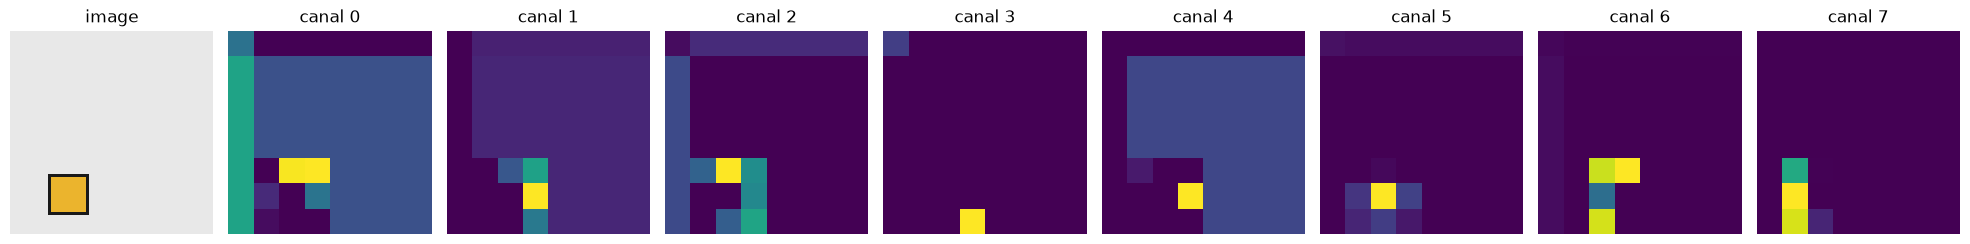

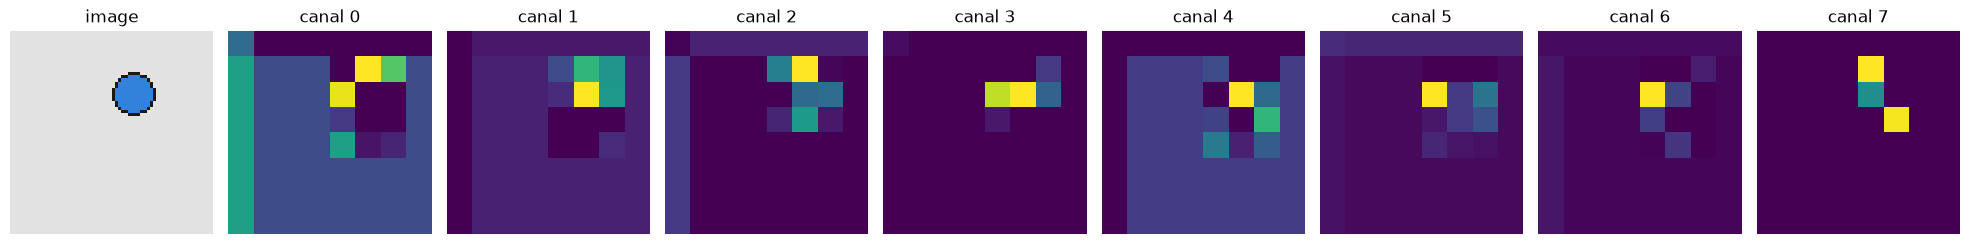

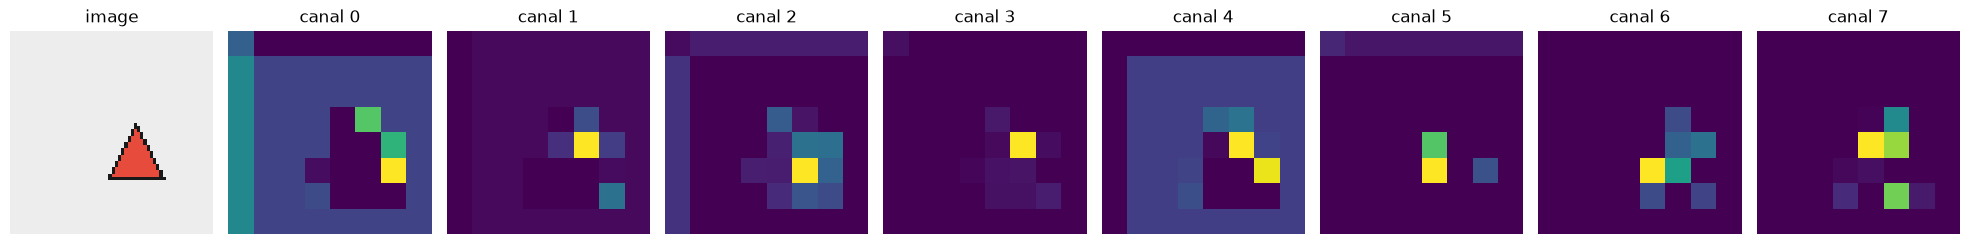

In [8]:
model2.eval()
with torch.no_grad():
    maps = model2.feature_maps(images_val[:3])     # (3, 32, 8, 8)
for i in range(3):
    show_feature_maps(images_val[i], maps[i], n_maps=8)

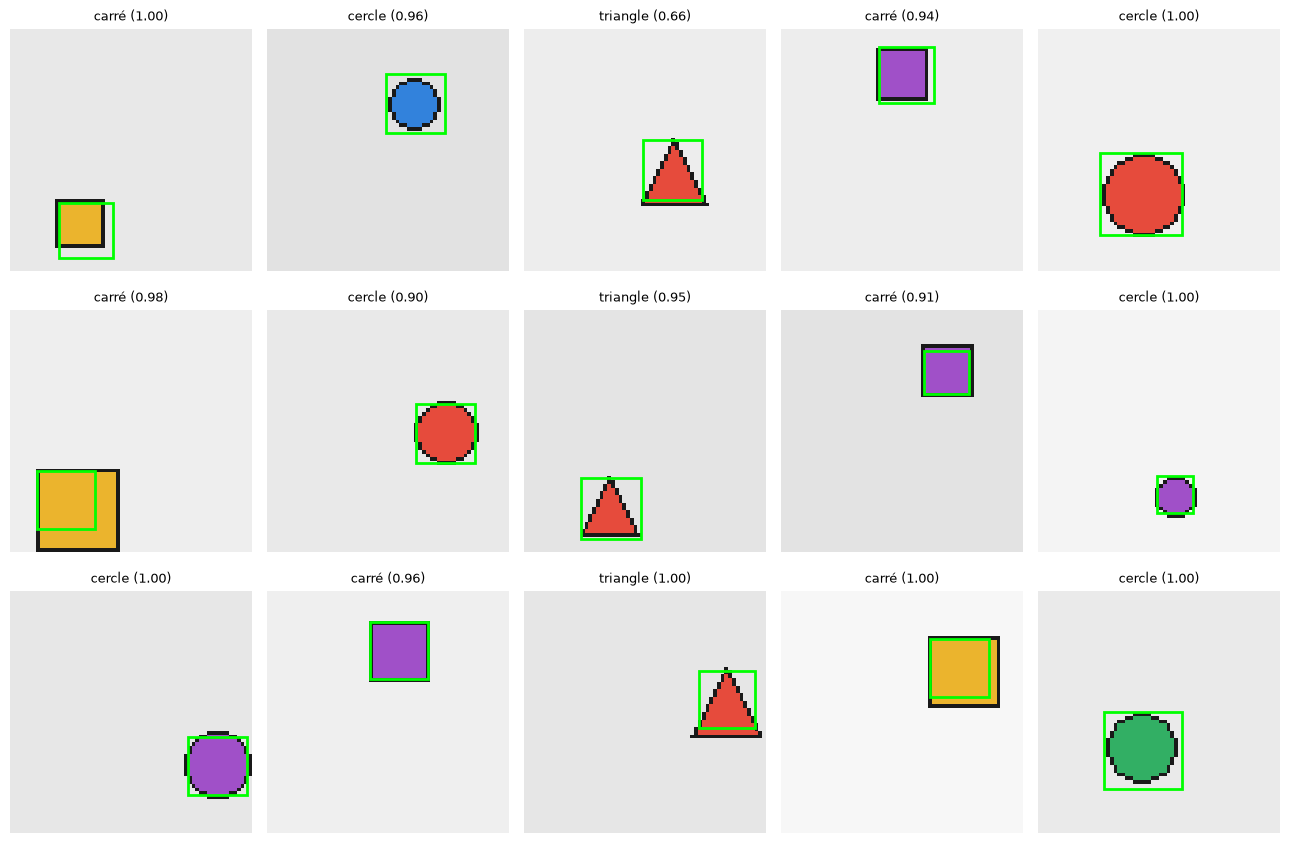

In [9]:
with torch.no_grad():
    logits = model2(images_val[:15])
results = [predict(l, SIZE) for l in logits]
true_classes = []
for t in targets_val[:15]:
    row, col = divmod(int(t[0].argmax()), t.shape[-1])
    true_classes.append(int(t[5, row, col]))
show_detections(list(images_val[:15]), [b for b, _, _ in results], [s for _, s, _ in results],
                [c for _, _, c in results], true_classes)

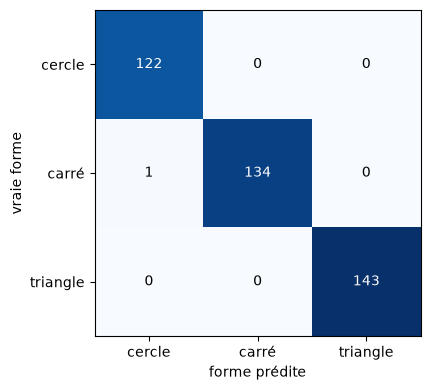

In [10]:
confusion = hist2["final"]["confusion"].numpy()
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(3), CLASSES)
ax.set_yticks(range(3), CLASSES)
ax.set(xlabel="forme prédite", ylabel="vraie forme")
for i in range(3):
    for j in range(3):
        ax.text(j, i, int(confusion[i, j]), ha="center", va="center",
                color="white" if confusion[i, j] > confusion.max() / 2 else "black")
fig.tight_layout()
fig.savefig("outputs/matrice_confusion.png", dpi=150)
plt.show()

In [11]:
%load_ext tensorboard
%tensorboard --logdir runs

Reusing TensorBoard on port 6006 (pid 25024), started 2 days, 7:01:14 ago. (Use '!kill 25024' to kill it.)